# Dimension Reduction in Magnetohydrodynamics Power Generation Models: Dimensional Analysis and Active Subspaces

__Andrew Glaws__, Department of Computer Science, University of Colorado, Boulder

__Paul Constantine__, Department of Computer Science, University of Colorado, Boulder

__John Shadid__, Center for Computing Research, Sandia National Laboratories, and Department of Mathematics and Statistics, University of New Mexico

__Timothy Wildey__, Center for Computing Research, Sandia National Laboratories

__Ryan Howard__ (2016 notebook)

The MHD generator data in this directory were computed with __Sandia National Laboratories__' Drekar multiphysics code [3], [4]. Please credit Sandia National Laboratories when you use them (see `DATA.md`).

<br>

In this notebook, we'll be summarizing the active subspaces and dimensional analysis methodologies and results on two MHD power generation models, presented in [[1]][R1]. The affiliations are those of the published paper. The analysis uses the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and runs in Python 3 with numpy, scipy and matplotlib (see the repository's `requirements.txt`). It takes about 15 seconds.

### Introduction

Magnetohydrodynamics (MHD) is the study of electrically conducting fluids, and one application of this area of physics is increasing the efficiency of power generation. To reasonably incorporate theory into practical generator design, it is important to know how model predictions will change when input parameters change. Some sensitivity analysis methods reduce the dimension of the input space by identifying important combinations of input parameters; less important combinations could be ignored with negligible loss of accuracy, and this can enable parameter studies that would otherwise be infeasible due to the expense of simulations. Here, we'll discuss the more traditional dimension reduction technique of _dimensional analysis_, an emerging method called _active subspaces_, their connection, and their results on two MHD models.

### Dimension Reduction

In this section, we consider dimension reduction on models that return a scalar quantity of interest, $y$, that depends on the model's $m$ input parameters, $\mathbf x$: $y = f(\mathbf x)$. We discuss dimensional analysis and active subspaces in turn.

##### Dimensional Analysis

The inputs and outputs of models are generally quantities that have physical units, most of which are derived from $k\leq m$ base units, denoted $L_1, \dots, L_k$ (e.g. a subset of the seven SI units). The _unit function_ returns the units of its argument and is denoted with square brackets, e.g. if $y$ is a velocity, then $[y]$ = m$\cdot$s$^{-1}$. We can write the units of the inputs, $\mathbf x = [x_1, x_2, \dots, x_m]^T$ and output, $y$, as

$$
[x_j] = \prod_{i=1}^k L_i^{d_{i, j}},\ [y] = \prod_{i=1}^k L_i^{u_i},
$$

and we define the matrix $\mathbf D$ and vector $\mathbf u$ as

$$
\mathbf D = \left[\begin{matrix}d_{1,1} & \cdots & d_{1, m}\\ \vdots & \ddots & \vdots \\ d_{k,1} & \cdots & d_{k, m}\end{matrix}\right],\ \mathbf u = \left[\begin{matrix}u_1\\\vdots\\u_k\end{matrix}\right].
$$

Let $r$ be the rank of $\mathbf D$. Now, let $\mathbf v$ satisfy $\mathbf D\mathbf v = \mathbf u$ and let $\mathbf U\in R^{m\times n}$, $n = m - r$, be a basis for $\mathbf D$'s null space: $\mathbf D \mathbf U = \mathbf 0$. We write $U_{i,j}$ for the entries of $\mathbf U$ and $\mathbf U_{:,j}$ for its columns. We can construct a unitless quantity of interest, $\Pi$, as

$$
\Pi = y\prod_{i=1}^mx_i^{-v_i},
$$

where $v_i$ is the $i^{th}$ component of $\mathbf v$, and unitless parameters, $\Pi_j$ as

$$
\Pi_j = \prod_{i=1}^mx_i^{U_{i,j}},\ j=1,\dots,n.
$$

The Buckingham Pi Theorem states that $\Pi = \tilde f(\mathbf\Pi),\ \mathbf\Pi = [\Pi_1,\dots,\Pi_n]^T$, i.e., that our law, $y=f(\mathbf x)$, can be characterized in unitless form with $n < m$ parameters (when $r > 0$).

##### Active Subspaces

The active subspace method is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\nabla f(\mathbf x)^T\gamma(\mathbf x)\ d\mathbf x = \mathbf W\Lambda\mathbf W^T,
$$

where $\nabla f(\mathbf x)$ is the gradient of $f$ with respect to $\mathbf x$, $\gamma(\mathbf x)$ is a probability density on $\mathbf x$, and $\mathbf W\Lambda\mathbf W^T$ is the eigendecomposition of $\mathbf C$ (with the eigenvalues in descending order). If $\lambda_n > \lambda_{n+1}$ for some $n < m$, we can partition the decomposition as

$$
\Lambda = \left[\begin{matrix}\Lambda_1 & \\ & \Lambda_2 \end{matrix}\right],\ \mathbf W = \left[\begin{matrix}\mathbf W_1 & \mathbf W_2\end{matrix}\right],
$$

where $\Lambda_1$ contains the first $n$ eigenvalues and $\mathbf W_1$ the corresponding vectors. The active subspace is the span of $\mathbf W_1$'s columns and the active variables are $\mathbf y = \mathbf W_1^T\mathbf x$. The inactive subspace is the span of $\mathbf W_2$'s columns and the inactive variables are $\mathbf z = \mathbf W_2^T\mathbf x$. The eigenvalues quantify how much $f$ changes, on average, in these two subspaces ([[1]][R1], Eq. (11); [[2]][R2], Lemma 2.2):

$$
\lambda_1 + \cdots + \lambda_n = \int\nabla_{\mathbf y} f(\mathbf x)^T\nabla_{\mathbf y} f(\mathbf x)\gamma(\mathbf x)\ d\mathbf x,\\
\lambda_{n+1} + \cdots + \lambda_m = \int\nabla_{\mathbf z} f(\mathbf x)^T\nabla_{\mathbf z} f(\mathbf x)\gamma(\mathbf x)\ d\mathbf x,
$$

where $\nabla_{\mathbf y}$ and $\nabla_{\mathbf z}$ are gradients with respect to the active and inactive variables. If $\lambda_{n+1},\dots,\lambda_m$ are small compared to the first $n$ values, we can approximate $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x),\ g:R^n\rightarrow R$. $\mathbf C$ must be approximated with a numerical integration rule, simple Monte Carlo for example: draw $\{\mathbf x_j\}_{j=1}^M$ from $\gamma$, compute gradients at each point, and approximate $\mathbf C\approx\hat{\mathbf C} = \frac 1 M\sum_{j=1}^M\nabla f(\mathbf x_j)\nabla f(\mathbf x_j)^T = \hat{\mathbf W}\hat\Lambda\hat{\mathbf W}^T$.

##### Connecting Dimensional Analysis With Active Subspaces

We can uncover a connection between dimensional analysis and active subspaces by rewriting the unitless form of our law:

$$
\begin{align}
y\prod_{i=1}^mx_i^{-v_i} &= \tilde f\left(\prod_{i=1}^mx_i^{U_{i,1}},\dots,\prod_{i=1}^mx_i^{U_{i,n}}\right) \\ &= \tilde f\left(\exp\left(\log\left(\prod_{i=1}^mx_i^{U_{i,1}}\right)\right),\dots,\exp\left(\log\left(\prod_{i=1}^mx_i^{U_{i,n}}\right)\right)\right) \\ &= \tilde f\left(\exp\left(\sum_{i=1}^mU_{i,1}\log(x_i)\right),\dots,\exp\left(\sum_{i=1}^mU_{i,n}\log(x_i)\right)\right) \\ &= \tilde f\left(\exp(\mathbf U_{:,1}^T\log(\mathbf x)),\dots,\exp(\mathbf U_{:,n}^T\log(\mathbf x))\right) \\\Rightarrow y &= \exp(\mathbf v^T\log(\mathbf x))\cdot \tilde f\left(\exp(\mathbf U_{:,1}^T\log(\mathbf x)),\dots,\exp(\mathbf U_{:,n}^T\log(\mathbf x))\right) \\ &= \tilde g(\mathbf A^T\log(\mathbf x)),\ \mathbf A = \left[\begin{matrix}\mathbf v & \mathbf U_{:,1} & \cdots & \mathbf U_{:,n}\end{matrix}\right]\in R^{m\times(n+1)}.
\end{align}
$$

Let $\tilde{\mathbf x} = \log(\mathbf x)$; by the chain rule, $\nabla_{\tilde{\mathbf x}}\tilde g(\mathbf A^T\tilde{\mathbf x}) = \mathbf A \nabla\tilde g(\mathbf A^T\tilde{\mathbf x})$. Let $\tilde\gamma(\tilde{\mathbf x})$ be a pdf on $\tilde{\mathbf x}$; then

$$
\int\nabla_{\tilde{\mathbf x}}\tilde g(\mathbf A^T\tilde{\mathbf x})\nabla_{\tilde{\mathbf x}}\tilde g(\mathbf A^T\tilde{\mathbf x})^T\tilde\gamma(\tilde{\mathbf x})\ d\tilde{\mathbf x} = \mathbf A\left(\int\nabla\tilde g(\mathbf A^T\tilde{\mathbf x})\nabla\tilde g(\mathbf A^T\tilde{\mathbf x})^T\tilde\gamma(\tilde{\mathbf x})\ d\tilde{\mathbf x}\right)\mathbf A^T.
$$

This shows that the physical law's active subspace (in terms of its log inputs) has dimension at most $n+1$ and is a subspace of $\mathbf A$'s column space. ([[1]][R1], p. 316, prints "at least $n + 1$", a typo: its Eq. (20) bounds the dimension from above.)

### Dimensional analysis for MHD

Under simplifying assumptions, the equations of steady-state MHD can be written as ([[1]][R1], Eq. (21))

$$
\begin{align}
\nabla\cdot\left[\rho\,\mathbf u\otimes\mathbf u + (p_0+p)\mathbf I - \mu(\nabla\mathbf u + \nabla\mathbf u^T) - \frac{1}{\mu_0}\left(\mathbf B\otimes\mathbf B - \frac 1 2\|\mathbf B\|^2\mathbf I\right)\right] &= \mathbf 0,\\
\nabla\cdot\left[\mathbf u\otimes\mathbf B - \mathbf B\otimes\mathbf u - \frac{\eta}{\mu_0}(\nabla\mathbf B - \nabla\mathbf B^T)\right] &= \mathbf 0,\\
\nabla\cdot\mathbf u = 0,\qquad \nabla\cdot\mathbf B &= 0,
\end{align}
$$

where $\mathbf u$ is the fluid velocity, $\mathbf B$ is the magnetic field, $p$ is the fluid pressure, and $p_0$ is the applied pressure. Five parameters appear in these equations: the fluid viscosity $\mu$, the fluid density $\rho$, the applied pressure gradient $\nabla p_0$, the magnetic resistivity $\eta$ and the vacuum permeability $\mu_0$. Two more are needed to describe the system: an applied magnetic field $B_0$, which enters through the boundary conditions, and a length scale $\ell$, the size of the channel. Dimensional analysis of the equations also needs a velocity $v$, from the unknown $\mathbf u$. The necessary base units are length ($L$), time ($T$), mass ($M$), and electrical current ($C$). The quantities and their units are summarized in the table below ([[1]][R1], Section 3.1).

Quantity | Symbol | Units
:---------|:------:|:----:
Length | $\ell$ | $L$
Velocity | $v$ | $\frac L T$
Fluid viscosity | $\mu$ | $\frac{M}{LT}$
Fluid density | $\rho$ | $\frac{M}{L^3}$
Pressure gradient | $\nabla p_0$ | $\frac{M}{L^2T^2}$
Magnetic resistivity | $\eta$ | $\frac{ML^3}{T^3C^2}$
Magnetic field | $B_0$ | $\frac{M}{T^2C}$
Vacuum permeability | $\mu_0$ | $\frac{ML}{T^2C^2}$

The dimension matrix of these 8 quantities has rank 4, so the Buckingham Pi Theorem says the system depends on 4 unitless parameters. Following the machinery presented above, these can be taken to be ([[1]][R1], Eq. (24)) the Reynolds number, the Hartmann number, the magnetic Reynolds number and a dimensionless pressure gradient:

$$
Re = \frac{\ell v\rho}{\mu},\quad Ha = \frac{\ell B_0}{\mu^{1/2}\eta^{1/2}},\quad Rm = \frac{\ell v\mu_0}{\eta},\quad \frac{\ell\,\nabla p_0}{v^2\rho}.
$$

For the connection with active subspaces, [[1]][R1] (Section 3.2) treats the seven parameters $\ell$, $\mu$, $\rho$, $\nabla p_0$, $\eta$, $B_0$, $\mu_0$ as the inputs $\mathbf x$ and a scalar functional of the solution, such as an average velocity or an induced magnetic field, as the output $y$. The dimension matrix of the seven inputs has rank 4, so $n = 3$ and $\mathbf A$ has $n + 1 = 4$ columns ([[1]][R1], Eqs. (32) and (35)): a particular quantity of interest will depend on at most 4 linear combinations of log-parameters. Fixing $\ell$ and $\mu_0$, as we do below, leaves 5 inputs and does not change this bound.

### References:

[[1]][R1] A. Glaws, P.G. Constantine, J.N. Shadid, and T.M. Wildey. _Dimension reduction in magnetohydrodynamics power generation models: dimensional analysis and active subspaces_. Stat. Anal. Data Min., 10(5):312–325, 2017. doi:10.1002/sam.11355 ([arXiv:1609.01255][R1a])

[[2]][R2] P.G. Constantine, E. Dow, and Q. Wang. _Active subspace methods in theory and practice: applications to kriging surfaces_. SIAM J. Sci. Comput., 36(4):A1500–A1524, 2014. doi:10.1137/130916138

[3] R.P. Pawlowski, J.N. Shadid, T.M. Smith, E.C. Cyr, and P.D. Weber. _Drekar::CFD—a turbulent fluid-flow and conjugate heat transfer code. Theory manual (version 1.0)_. Technical Report SAND2012-2697, Sandia National Laboratories, 2012

[4] J.N. Shadid, T.M. Smith, E.C. Cyr, T.M. Wildey, and R.P. Pawlowski. _Stabilized FE simulation of prototype thermal-hydraulics problems with integrated adjoint-based capabilities_. J. Comput. Phys., 321:321–341, 2016

[R1]: https://doi.org/10.1002/sam.11355
[R1a]: https://arxiv.org/abs/1609.01255
[R2]: https://doi.org/10.1137/130916138

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

<br>

### MHD Active Subspaces

We'll now look at two MHD models and apply active subspaces to them, using the [active_subspaces](https://github.com/paulcon/active_subspaces) library.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import roots_legendre
import active_subspaces as ac
from hartmann_model import uavg, Bind, uavg_grad, Bind_grad, NAMES, LABELS, LOWER, UPPER

t_start = time.perf_counter()
rng = np.random.default_rng(2017)        # the only source of randomness in this notebook
np.set_printoptions(precision=4, suppress=False, linewidth=120)


def fmt(v):
    # One eigenvector as signed components, in the order of NAMES.
    return ', '.join(f'{n} {c:+.3f}' for n, c in zip(NAMES, v))


def plot_case(sub, X, f, qoi_label, title, interval=None):
    # The four panels of [1], Figs. 2, 3, 5 and 6: eigenvalues, w1 and w2, and the
    # one- and two-dimensional sufficient summary plots at the physical (log) inputs X.
    fig = plt.figure(figsize=(15, 9), layout='constrained')
    top, bottom = fig.subfigures(2, 1)
    ax = top.subplots(1, 3)
    ac.plotting.plot_eigenvalues(sub, interval=interval, ax=ax[0])
    ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=LABELS, ax=ax[1:])
    ax[1].tick_params(axis='x', labelbottom=True, labelrotation=90)
    bx = bottom.subplots(1, 2)
    for b, dims in zip(bx, (1, 2)):
        ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=dims, qoi_label=qoi_label, ax=b)
    fig.suptitle(title, fontsize=16)
    plt.show()

##### The Hartmann Problem

The Hartmann problem models laminar flow between two parallel plates a distance $2\ell$ apart, with a uniform magnetic field applied perpendicular to the flow, and admits closed-form analytical solutions in terms of its input parameters. We examine two quantities of interest: average flow velocity, $u_{avg}$, and the induced magnetic field, $B_{ind}$, whose solutions are ([[1]](https://doi.org/10.1002/sam.11355), Eqs. (36) and (37))

$$
u_{avg} = -\frac{\partial p_0}{\partial x}\frac{\eta}{B_0^2}\left(1 - \frac{B_0\ell}{\sqrt{\eta\mu}}\coth\left(\frac{B_0\ell}{\sqrt{\eta\mu}}\right)\right), \\
B_{ind} = \frac{\partial p_0}{\partial x}\frac{\ell\mu_0}{2B_0}\left(1 - 2\frac{\sqrt{\eta\mu}}{B_0\ell}\tanh\left(\frac{B_0\ell}{2\sqrt{\eta\mu}}\right)\right).
$$

This has 5 input parameters, $\mathbf x = \left[\begin{matrix}\log(\mu) & \log(\rho) & \log(\frac{\partial p_0}{\partial x}) & \log(\eta) & \log(B_0)\end{matrix}\right]^T$. The length $\ell$ and the vacuum permeability $\mu_0$ are fixed. As in [[1]](https://doi.org/10.1002/sam.11355) (p. 318), $\ell = 1$. [[1]](https://doi.org/10.1002/sam.11355) does not state $\mu_0$ for the Hartmann problem; we set $\mu_0 = 1$, as the 2016 version of this notebook did and as [[1]](https://doi.org/10.1002/sam.11355) does for the generator below (the authors confirm this value). $\mu_0$ only scales $B_{ind}$: the eigenvalues for $B_{ind}$ are proportional to $\mu_0^2$, and the eigenvectors do not depend on it. Neither quantity depends on $\rho$. We choose $\gamma$ to be a uniform density on the log-inputs, with ranges summarized below ([[1]](https://doi.org/10.1002/sam.11355), Table 2).

Variable | $\ $ Notation $\ $ | Range $\ \ \ \ \ $
:--------|:--------:|:------------
Fluid Viscosity | $\log(\mu)$ | [log(.05), log(.2)]
Fluid Density | $\log(\rho)$ | [log(1), log(5)]
Applied Pressure Gradient | $\log(\frac{\partial p_0}{\partial x})$ | [log(.5), log(3)]
Resistivity | $\log(\eta)$ | [log(.5), log(3)]
Applied Magnetic Field | $\log(B_0)$ | [log(.1), log(1)]

The two functions and their gradients with respect to the log-inputs are in `hartmann_model.py`, next to this notebook, with $\ell = \mu_0 = 1$ as defaults. First we check the gradients against central finite differences at 100 random points.

In [2]:
space_h = ac.Uniform(lower=np.log(LOWER), upper=np.log(UPPER), names=NAMES)

x = space_h.sample(100, rng=rng)
h = 1e-6
for f, grad in [(uavg, uavg_grad), (Bind, Bind_grad)]:
    fd = np.stack([(f(x + h*e) - f(x - h*e)) / (2*h) for e in np.eye(5)], axis=-1)
    g = grad(x)
    print(f'{f.__name__}: max error of the gradient vs finite differences = '
          f'{np.max(np.abs(fd - g)) / np.max(np.abs(g)):.1e} (relative to the largest component)')

uavg: max error of the gradient vs finite differences = 1.1e-09 (relative to the largest component)
Bind: max error of the gradient vs finite differences = 1.2e-09 (relative to the largest component)


We approximate the integral defining $\mathbf C$ with a tensor-product Gauss-Legendre rule with 11 points in each of the 5 dimensions (totaling 161,051 points), as in [[1]](https://doi.org/10.1002/sam.11355). The one-dimensional weights are halved so that they sum to 1 on $[-1, 1]$, and so the tensor weights already include the uniform density $\gamma = 2^{-5}$ on the normalized inputs. The 2016 version of this notebook multiplied the integrand by $2^{-5}$ a second time, which made every Hartmann eigenvalue 32 times too small; its eigenvalue plots show $\lambda_1 \approx 1$ for $u_{avg}$ (printed below). The eigenvectors do not depend on that factor.

`ac.active_subspace` takes the gradients with respect to the log-inputs and the quadrature weights, and scales the gradients by $(\log x_{\text{upper}} - \log x_{\text{lower}})/2$ to the normalized inputs in $[-1, 1]^5$ itself. We keep $n = 2$ dimensions, as in [[1]](https://doi.org/10.1002/sam.11355). v1 makes each eigenvector's largest component positive; we use `ac.orient` to restore the 2016 rule (first component positive), which also gives the signs of the figures in [[1]](https://doi.org/10.1002/sam.11355).

In [3]:
t, w = roots_legendre(11)
w = w / 2                                 # 1-D weights summing to 1 on [-1, 1]
T = np.stack(np.meshgrid(*[t]*5, indexing='ij'), axis=-1).reshape(-1, 5)
quad_w = np.prod(np.stack(np.meshgrid(*[w]*5, indexing='ij'), axis=-1).reshape(-1, 5), axis=1)
X_h = space_h.from_normalized(T)          # quadrature nodes as log-inputs
print(f'{quad_w.size:,} points; sum of the weights - 1 = {quad_w.sum() - 1:.1e}')

FIRST = np.eye(5)[:, [0, 0]]              # orient: first component of w1 and w2 positive (2016 rule)
hart = {}
for qoi, grad in [('u_avg', uavg_grad), ('B_ind', Bind_grad)]:
    s = ac.active_subspace(space=space_h, grads=grad(X_h), quad_weights=quad_w, n=2, qoi=qoi)
    hart[qoi] = ac.orient(s, by='reference', reference=FIRST, columns=2)

for qoi, s in hart.items():
    lam = s.eigenvalues
    print(f'Hartmann {qoi}:')
    print('  eigenvalues           ', lam)
    print(f'  lambda1/lambda2 = {lam[0]/lam[1]:.1f}, max(lambda3..5)/lambda1 = {lam[2:].max()/lam[0]:.0e}')
    print('  2016 plot (x 2^-5)    ', lam[:2] * 2.**-5)
    print('  w1:', fmt(s.W[:, 0]))
    print('  w2:', fmt(s.W[:, 1]))

161,051 points; sum of the weights - 1 = 8.9e-16
Hartmann u_avg:
  eigenvalues            [3.6570e+01 1.2275e+00 1.2456e-30 1.0509e-31 1.9650e-37]
  lambda1/lambda2 = 29.8, max(lambda3..5)/lambda1 = 3e-32
  2016 plot (x 2^-5)     [1.1428 0.0384]
  w1: log mu +0.572, log rho +0.000, log dp0/dx -0.802, log eta -0.062, log B0 +0.160
  w2: log mu +0.276, log rho +0.000, log dp0/dx -0.009, log eta +0.348, log B0 -0.896
Hartmann B_ind:
  eigenvalues            [8.6261e-02 6.3541e-03 2.4211e-33 5.6722e-34 7.8536e-37]
  lambda1/lambda2 = 13.6, max(lambda3..5)/lambda1 = 3e-32
  2016 plot (x 2^-5)     [0.0027 0.0002]
  w1: log mu +0.381, log rho +0.000, log dp0/dx -0.663, log eta +0.493, log B0 -0.414
  w2: log mu +0.031, log rho -0.000, log dp0/dx +0.563, log eta +0.040, log B0 -0.825


Now we plot the eigenvalues, the first 2 eigenvectors, and 1- and 2-dimensional summary plots (plots of the active variable(s) vs data values; tight trends indicate active subspaces) for $u_{avg}$. The summary plots use 5000 of the quadrature nodes, drawn at random.

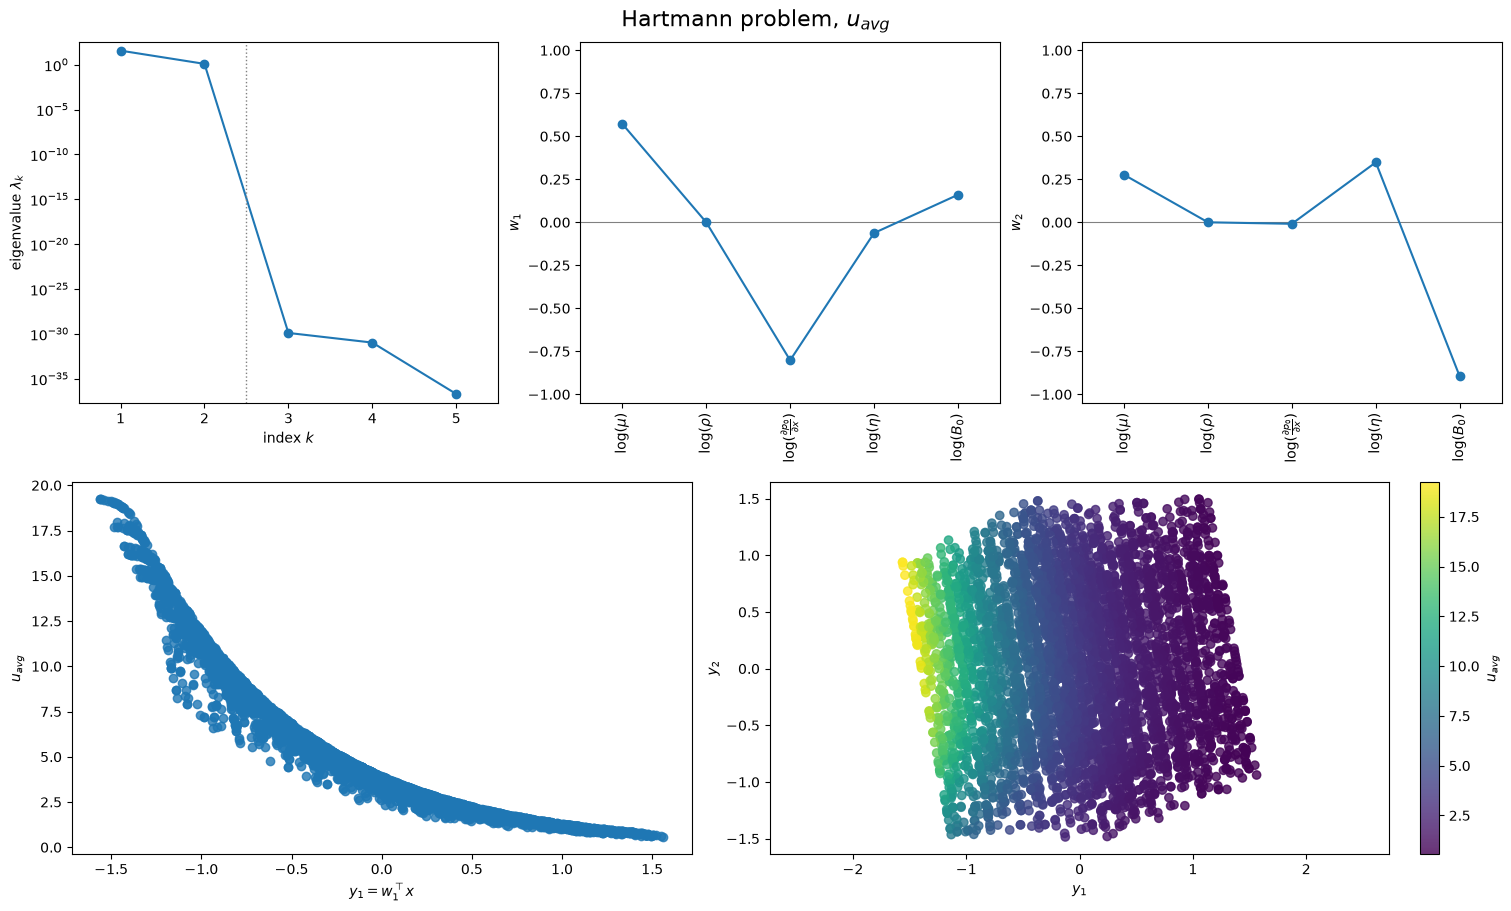

In [4]:
mask = rng.choice(X_h.shape[0], 5000, replace=False)
plot_case(hart['u_avg'], X_h[mask], uavg(X_h[mask]), r'$u_{avg}$', r'Hartmann problem, $u_{avg}$')

The second eigenvalue is more than an order of magnitude smaller than the first ($\lambda_1/\lambda_2 = 29.8$), so we would expect the presence of a 1-dimensional subspace, and the eigenvalues past the second are zero to rounding error (at most $3\times 10^{-32}\lambda_1$), indicating that a 2-dimensional subspace should completely characterize our output. These expectations are confirmed in the summary plots; the 1-dimensional plot has a tight (but imperfect) trend and the 2-dimensional plot shows a perfect trend. The eigenvectors provide a measure of global sensitivity; higher-magnitude components indicate more sensitivity to the corresponding parameter. For example, neither vector places any weight on $\log(\rho)$, which we would expect since $u_{avg}$ is independent of $\rho$.

The eigenvectors match [[1]](https://doi.org/10.1002/sam.11355), Fig. 2B, including the signs. [[1]](https://doi.org/10.1002/sam.11355) (p. 319) describes the gap between $\lambda_1$ and $\lambda_2$ as three orders of magnitude, but its own Fig. 2A shows $\lambda_1 \approx 1.4$ and $\lambda_2 \approx 0.05$, a ratio of about 28. That figure's scale also matches the 2016 values printed above ($\lambda_1 = 1.14$, $\lambda_2 = 0.038$), so it appears to carry the same extra factor $2^{-5}$.

Now we repeat the process for $B_{ind}$.

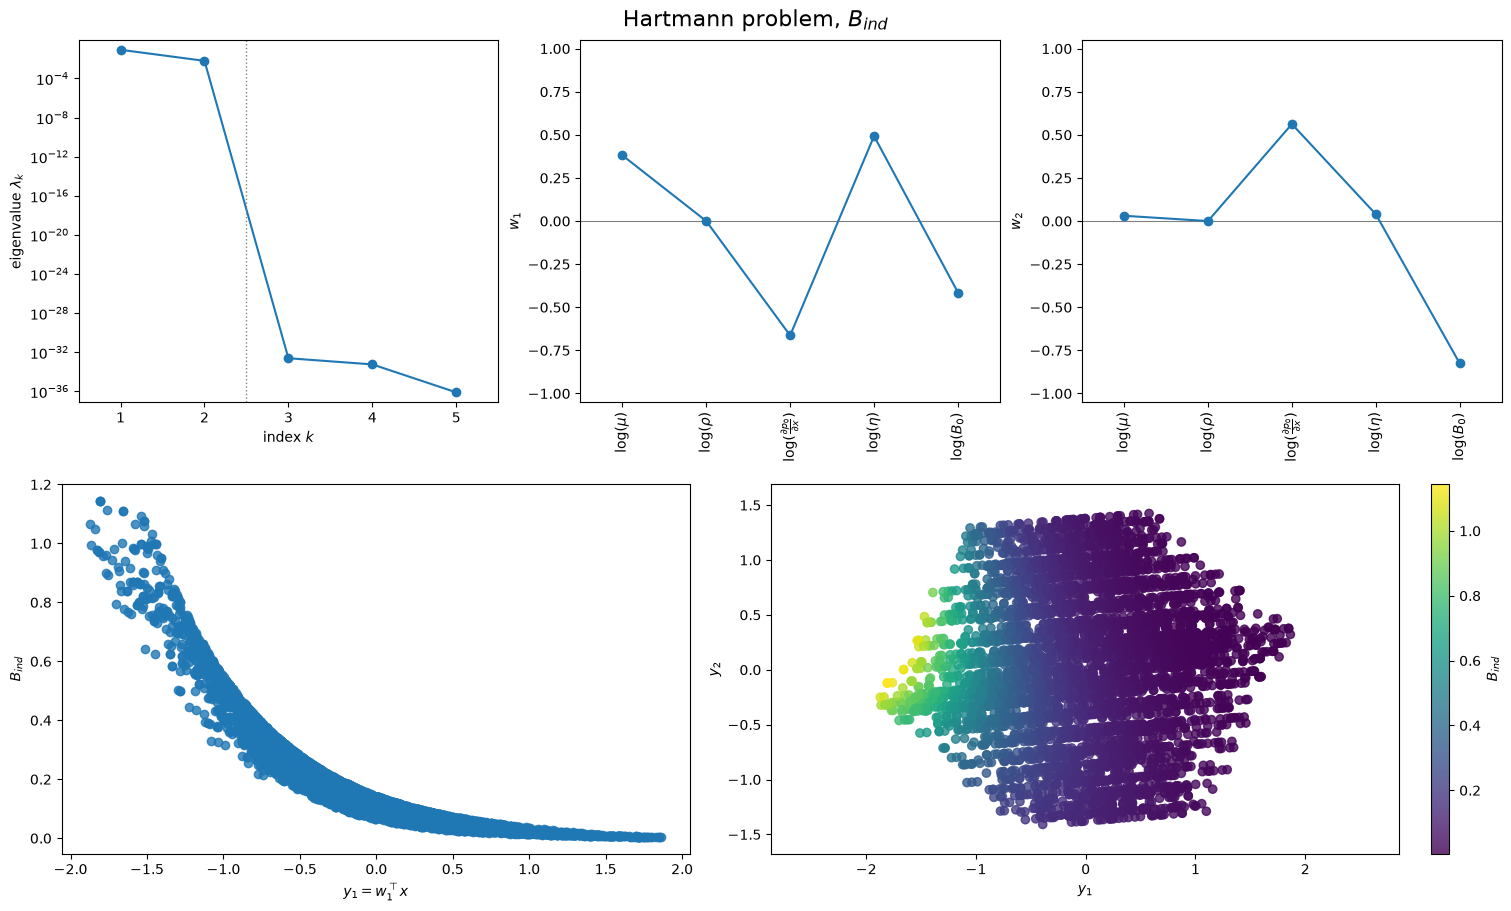

In [5]:
plot_case(hart['B_ind'], X_h[mask], Bind(X_h[mask]), r'$B_{ind}$', r'Hartmann problem, $B_{ind}$')

We can make similar observations for $B_{ind}$: a tight 1-dimensional plot and a perfect 2-dimensional plot, as we would expect from the similar eigenvalue decay compared to $u_{avg}$ ($\lambda_1/\lambda_2 = 13.6$, and the eigenvalues past the second are zero to rounding error). The 1-dimensional plot departs most from a univariate trend when the first active variable is negative, as [[1]](https://doi.org/10.1002/sam.11355) notes for its Fig. 3C.

__These $B_{ind}$ results differ from [[1]](https://doi.org/10.1002/sam.11355), Fig. 3.__ With $\ell = \mu_0 = 1$, the first eigenvector printed above is $\mathbf w_1 = [0.381, 0, -0.663, 0.493, -0.414]$. In [[1]](https://doi.org/10.1002/sam.11355), Fig. 3B, it is about $[0.38, 0, -0.56, 0.49, -0.56]$: the components for $\log(\frac{\partial p_0}{\partial x})$ and $\log(B_0)$ differ. Fig. 3A also shows $\lambda_1 \approx 3$ and $\lambda_1/\lambda_2 \approx 45$, against $\lambda_1 = 0.0863$ and a ratio of 13.6 here. $\mu_0$ cannot explain the difference (it only scales the eigenvalues), and it is not known how Fig. 3 was computed. The $u_{avg}$ results above match [[1]](https://doi.org/10.1002/sam.11355), Fig. 2B.

The dimensional analysis above indicated that the quantities of interest should depend on 4 unitless parameters; we might wonder why our active subspace is only 2-dimensional. To see why this happens, we rewrite the quantities of interest in terms of the Reynolds, Hartmann and magnetic Reynolds numbers ($Re$, $Ha$ and $Rm$) and a unitless pressure gradient ([[1]](https://doi.org/10.1002/sam.11355), Eqs. (39) and (40)):

$$
u_{avg}^* = -\frac{\partial p_0^*}{\partial x^*}\frac{Re}{Ha^2}(1 - Ha\coth(Ha)),\\
B_{ind}^* = \frac{\partial p_0^*}{\partial x^*}\frac{Re}{Ha}Rm\left(1 - \frac{2}{Ha}\tanh\left(\frac{Ha}{2}\right)\right).
$$

Several of the unitless quantities appear only as a product (the Reynolds number and dimensionless pressure gradient for $u_{avg}$, and those two with the magnetic Reynolds number for $B_{ind}$), which we could define as a new unitless quantity. Each quantity of interest then depends on only two unitless quantities. This explains why our active subspace has only 2 dimensions.

##### MHD Generator Problem

We now consider a model that describes steady 3D duct flow in an idealized MHD generator ([[1]](https://doi.org/10.1002/sam.11355), Section 4.2): a conducting fluid flows through a duct of dimensions 15 m × 1 m × 1 m with inlet velocity 1 m/s, through a vertical magnetic field of strength $B_0$ applied between $x_{on} = 4$ and $x_{off} = 6$ (with transition width $\delta = 0.1$), and $\mu_0 = 1$. The governing equations are the resistive MHD equations, a slightly modified version of the system above. The variable input parameters are the same as those in the Hartmann problem (with uniform densities on the log-inputs), but they have different ranges, summarized below ([[1]](https://doi.org/10.1002/sam.11355), Table 3).

Variable | $\ $ Notation $\ $ | Range $\ \ \ \ \ $
:--------|:--------:|:------------
Fluid Viscosity | $\log(\mu)$ | [log(.001), log(.01)]
Fluid Density | $\log(\rho)$ | [log(.1), log(10)]
Applied Pressure Gradient | $\log(\frac{\partial p_0}{\partial x})$ | [log(.1), log(.5)]
Resistivity | $\log(\eta)$ | [log(.1), log(10)]
Applied Magnetic Field | $\log(B_0)$ | [log(.1), log(1)]

Our quantities of interest are again $u_{avg}$ and $B_{ind}$. The solutions were computed with Sandia National Laboratories' Drekar multiphysics code [3], whose adjoint capabilities give the gradients of both quantities with respect to the inputs [4]. Each run of the model takes about 5.3 CPU-hours (ten minutes on 32 cores), so a Gauss-Legendre rule is infeasible. We instead use a Monte Carlo method with 483 samples from the input space.

The runs are stored in two files, one per quantity of interest. Each row holds an index label, the five inputs in physical units (not their logs), the quantity of interest, and its gradient with respect to the five physical inputs (`DATA.md` has the details). We first load them and check the labels, the input ranges, and that the gradients are with respect to the physical inputs: in the Hartmann problem both quantities are proportional to $\frac{\partial p_0}{\partial x}$, and for the generator the median of $\frac{\partial p_0}{\partial x}\,\partial f/\partial(\frac{\partial p_0}{\partial x})\,/\,f$ should then be close to 1.

In [6]:
def load(fname):
    # Index labels, physical inputs (M, 5), quantity of interest (M,), gradient w.r.t. the physical inputs (M, 5).
    D = np.loadtxt(fname, delimiter=',', skiprows=1)
    return D[:, 0].astype(int), D[:, 1:6], D[:, 6], D[:, 7:]


lo_g = np.array([.001, .1, .1, .1, .1])
hi_g = np.array([.01, 10, .5, 10, 1])
space_g = ac.Uniform(lower=np.log(lo_g), upper=np.log(hi_g), names=NAMES)

raw = {}
for qoi, fname in [('u_avg', 'MHD_Generator_Data_Uavg.txt'), ('B_ind', 'MHD_Generator_Data_Bind.txt')]:
    lab, X, f, df = raw[qoi] = load(fname)
    print(f'{fname}: {len(f)} rows, labels {lab.min()}..{lab.max()}, '
          f'missing labels {sorted(set(range(lab.max() + 1)) - set(lab))}')
    print(f'  all inputs inside the Table 3 ranges: {bool(np.all(space_g.contains(np.log(X))))}')
    print(f'  median of (dp0/dx) * df/d(dp0/dx) / f = {np.median(X[:, 2] * df[:, 2] / f):.4f}')
print('Same labels in both files:', np.array_equal(raw['u_avg'][0], raw['B_ind'][0]))

lab_u, X_u = raw['u_avg'][:2]
lab_B, X_B = raw['B_ind'][:2]
i, j = np.nonzero((X_u[:, None, :] == X_B[None, :, :]).all(axis=-1))   # rows with the same inputs
d = lab_u[i] - lab_B[j]
print(f'{len(i)} pairs of rows have the same inputs; u_avg label - B_ind label is 0 for {np.sum(d == 0)} '
      f'and {sorted(set(d[d != 0].tolist()))} for {np.sum(d != 0)} (u_avg labels {lab_u[i][d != 0].min()}..{lab_u[i][d != 0].max()})')
print('u_avg labels with no B_ind match:', np.setdiff1d(lab_u, lab_u[i]).tolist(),
      '; B_ind labels with no u_avg match:', np.setdiff1d(lab_B, lab_B[j]).tolist())

MHD_Generator_Data_Uavg.txt: 483 rows, labels 0..499, missing labels [5, 40, 72, 107, 115, 153, 253, 258, 295, 305, 309, 347, 398, 411, 453, 467, 470]
  all inputs inside the Table 3 ranges: True
  median of (dp0/dx) * df/d(dp0/dx) / f = 1.0002
MHD_Generator_Data_Bind.txt: 483 rows, labels 0..499, missing labels [5, 40, 72, 107, 115, 153, 253, 258, 295, 305, 309, 347, 398, 411, 453, 467, 470]
  all inputs inside the Table 3 ranges: True
  median of (dp0/dx) * df/d(dp0/dx) / f = 1.0060
Same labels in both files: True
482 pairs of rows have the same inputs; u_avg label - B_ind label is 0 for 434 and [1] for 48 (u_avg labels 50..99)
u_avg labels with no B_ind match: [73] ; B_ind labels with no u_avg match: [71, 99]


The labels run from 0 to 499 with 17 gaps, the same in both files; we take the gaps to be failed runs. But the same label does not always mean the same run: for the $u_{avg}$ rows labelled 50 to 99, the inputs are those of the $B_{ind}$ row labelled one less. Matching the input points across the files pins this down:

- **The shift.** In the $u_{avg}$ file, the row labelled $L$ holds the run labelled $L - 1$ in the $B_{ind}$ file, for every $L$ from 50 to 99 where both rows exist (48 pairs), and for no other label. Outside that block the labels agree (434 pairs).
- **The duplicate is the first row of the block.** The $u_{avg}$ rows labelled 49 and 50 are identical in every column: both hold run 49.
- **The unmatched points fit the same shift.** The $u_{avg}$ row labelled 73 holds run 72, which is one of the 17 gaps, and its gradient is a placeholder (the same value in four columns and 0 in the fifth; printed below), so it is a failed run. Run 71 would sit at $u_{avg}$ label 72, which is a gap, and run 99 at label 100, which holds run 100, so both are missing from the $u_{avg}$ file. They are the two $B_{ind}$ rows with no match.
- **One relabeling makes the files consistent.** Taking the $B_{ind}$ labels as run IDs and relabeling the $u_{avg}$ rows labelled 50 to 99 as $L - 1$, every run ID in both files has the same inputs in both, and every input point in both files has the same run ID. Relabeling the $B_{ind}$ file instead (labels 49 to 98 as $L + 1$) does not work: two $B_{ind}$ rows would get run ID 99.

Why the $u_{avg}$ rows of this block of 50 labels were shifted is not known, and the original Drekar output cannot be recovered. The rule only changes labels; the files themselves are unchanged. We apply it and then drop two kinds of rows: exact repeats of an earlier row (we keep the first), and runs in the list of 17 gaps. The code asserts each of the facts above.

In [7]:
GAPS = sorted(set(range(500)) - set(lab_B))                 # failed runs: the labels missing from both files
run = {'B_ind': lab_B.copy(), 'u_avg': lab_u.copy()}       # run IDs: the B_ind labels
block = (lab_u >= 50) & (lab_u <= 99)
run['u_avg'][block] -= 1                                    # u_avg rows labelled 50..99 hold runs 49..98

# The rule makes the files consistent: same inputs <=> same run ID.
assert np.array_equal(run['u_avg'][i], run['B_ind'][j])
for r in np.intersect1d(run['u_avg'], run['B_ind']):
    assert (X_u[run['u_avg'] == r] == X_B[run['B_ind'] == r]).all()
ids, counts = np.unique(run['u_avg'], return_counts=True)
assert ids[counts > 1].tolist() == [49] and len(set(run['B_ind'])) == len(run['B_ind'])
assert np.setdiff1d(run['u_avg'], run['B_ind']).tolist() == [72] and 72 in GAPS
assert np.setdiff1d(run['B_ind'], run['u_avg']).tolist() == [71, 99]
print(f'After relabeling u_avg labels 50..99 as L - 1: {len(np.intersect1d(run["u_avg"], run["B_ind"]))} runs are in both files '
      f'with the same inputs; run 49 appears twice in u_avg; run 72 (a gap) only in u_avg; runs 71 and 99 only in B_ind')
r72 = np.nonzero(run['u_avg'] == 72)[0][0]
X72, f72, df72 = raw['u_avg'][1][r72], raw['u_avg'][2][r72], raw['u_avg'][3][r72]
print(f'u_avg row labelled {lab_u[r72]} (run 72): gradient {df72.tolist()}, '
      f'(dp0/dx) * du/d(dp0/dx) / u = {X72[2]*df72[2]/f72:.1e}')

gen = {}
for qoi in ('u_avg', 'B_ind'):
    lab, X, f, df = raw[qoi]
    rows = np.column_stack([X, f, df])
    _, first = np.unique(rows, axis=0, return_index=True)
    repeat = ~np.isin(np.arange(len(f)), first)             # repeats an earlier row exactly
    failed = np.isin(run[qoi], GAPS)                        # a run in the list of gaps
    keep = ~(repeat | failed)
    gen[qoi] = run[qoi][keep], X[keep], f[keep], df[keep]
    print(f'{qoi}: dropped as exact repeats: labels {lab[repeat].tolist()}; as failed runs: labels '
          f'{lab[failed].tolist()} (run IDs {run[qoi][failed].tolist()}); {keep.sum()} rows kept')

After relabeling u_avg labels 50..99 as L - 1: 481 runs are in both files with the same inputs; run 49 appears twice in u_avg; run 72 (a gap) only in u_avg; runs 71 and 99 only in B_ind
u_avg row labelled 73 (run 72): gradient [0.0027695, 0.0027695, 0.0027695, 0.0027695, 0.0], (dp0/dx) * du/d(dp0/dx) / u = 1.0e-04
u_avg: dropped as exact repeats: labels [50]; as failed runs: labels [73] (run IDs [72]); 481 rows kept
B_ind: dropped as exact repeats: labels []; as failed runs: labels [] (run IDs []); 483 rows kept


The 2016 notebook used all 483 rows of each file. We first repeat that computation (no bootstrap), and then compute the subspaces from the kept rows with 500 bootstrap replicates, which we use from here on. Each quantity of interest uses all its own valid runs; neither analysis needs the other file. We also print the eigenvalues on only the runs that are in both files, to show that analyzing the files jointly would change little. As for the Hartmann problem, the gradients are with respect to the log-inputs: by the chain rule, $\partial f/\partial\log x_i = x_i\,\partial f/\partial x_i$, and `ac.active_subspace` scales them to the normalized inputs.

In [8]:
gen_all, gen_sub = {}, {}
for qoi in ('u_avg', 'B_ind'):
    lab, X, f, df = raw[qoi]
    gen_all[qoi] = ac.active_subspace(space=space_g, grads=X*df, n=2, qoi=qoi)
    _, X, f, df = gen[qoi]
    s = ac.active_subspace(space=space_g, grads=X*df, n=2, nboot=500, rng=rng, qoi=qoi)
    gen_sub[qoi] = ac.orient(s, by='reference', reference=FIRST, columns=2)
both = np.intersect1d(gen['u_avg'][0], gen['B_ind'][0])

for qoi in ('u_avg', 'B_ind'):
    lam_all, s = gen_all[qoi].eigenvalues, gen_sub[qoi]
    lam = s.eigenvalues
    r, X, f, df = gen[qoi]
    k = np.isin(r, both)
    lam_both = ac.active_subspace(space=space_g, grads=X[k]*df[k], n=2).eigenvalues
    band = ac.bootstrap_interval(s.bootstrap_eigenvalues, kind='minmax')
    print(f'Generator {qoi}:')
    print(f'  eigenvalues, all {len(raw[qoi][2])} rows    ', lam_all)
    print(f'  eigenvalues, {len(r)} kept rows   ', lam,
          f' (largest relative change {np.max(np.abs(lam/lam_all - 1)):.1e})')
    print(f'  eigenvalues, {k.sum()} runs in both files', lam_both,
          f' (largest relative change from the kept rows {np.max(np.abs(lam_both/lam - 1)):.1e})')
    print(f'  lambda1/lambda2 = {lam[0]/lam[1]:.1f}; lambda5 is {100*lam[4]/lam.sum():.6f}% of the sum '
          f'({100*lam_all[4]/lam_all.sum():.6f}% with all rows)')
    print(f'  bootstrap range (min, max) of lambda1: [{band[0, 0]:.4g}, {band[1, 0]:.4g}]')
    print('  w1:', fmt(s.W[:, 0]))
    print('  w2:', fmt(s.W[:, 1]))

Generator u_avg:
  eigenvalues, all 483 rows     [2.8977e+01 9.2767e-01 2.0178e-01 3.0625e-02 7.3250e-05]
  eigenvalues, 481 kept rows    [2.9081e+01 9.3145e-01 2.0262e-01 3.0753e-02 7.3213e-05]  (largest relative change 4.2e-03)
  eigenvalues, 481 runs in both files [2.9081e+01 9.3145e-01 2.0262e-01 3.0753e-02 7.3213e-05]  (largest relative change from the kept rows 0.0e+00)
  lambda1/lambda2 = 31.2; lambda5 is 0.000242% of the sum (0.000243% with all rows)
  bootstrap range (min, max) of lambda1: [22.72, 35.1]
  w1: log mu +0.828, log rho -0.018, log dp0/dx -0.557, log eta +0.036, log B0 -0.047
  w2: log mu +0.111, log rho -0.258, log dp0/dx +0.271, log eta +0.550, log B0 -0.738
Generator B_ind:
  eigenvalues, all 483 rows     [4.1558e-03 4.9398e-04 1.0977e-04 1.5817e-05 4.9221e-11]
  eigenvalues, 483 kept rows    [4.1558e-03 4.9398e-04 1.0977e-04 1.5817e-05 4.9221e-11]  (largest relative change 0.0e+00)
  eigenvalues, 481 runs in both files [4.1731e-03 4.9603e-04 1.1023e-04 1.5883e-

We present plots of the eigenvalues, first 2 eigenvectors, and summary plots, as for the Hartmann problem. The eigenvalue plot also includes the range (minimum to maximum) of the 500 bootstrap replicates, which assesses the variability in our estimates, as in [[1]](https://doi.org/10.1002/sam.11355). The summary plots use all the rows.

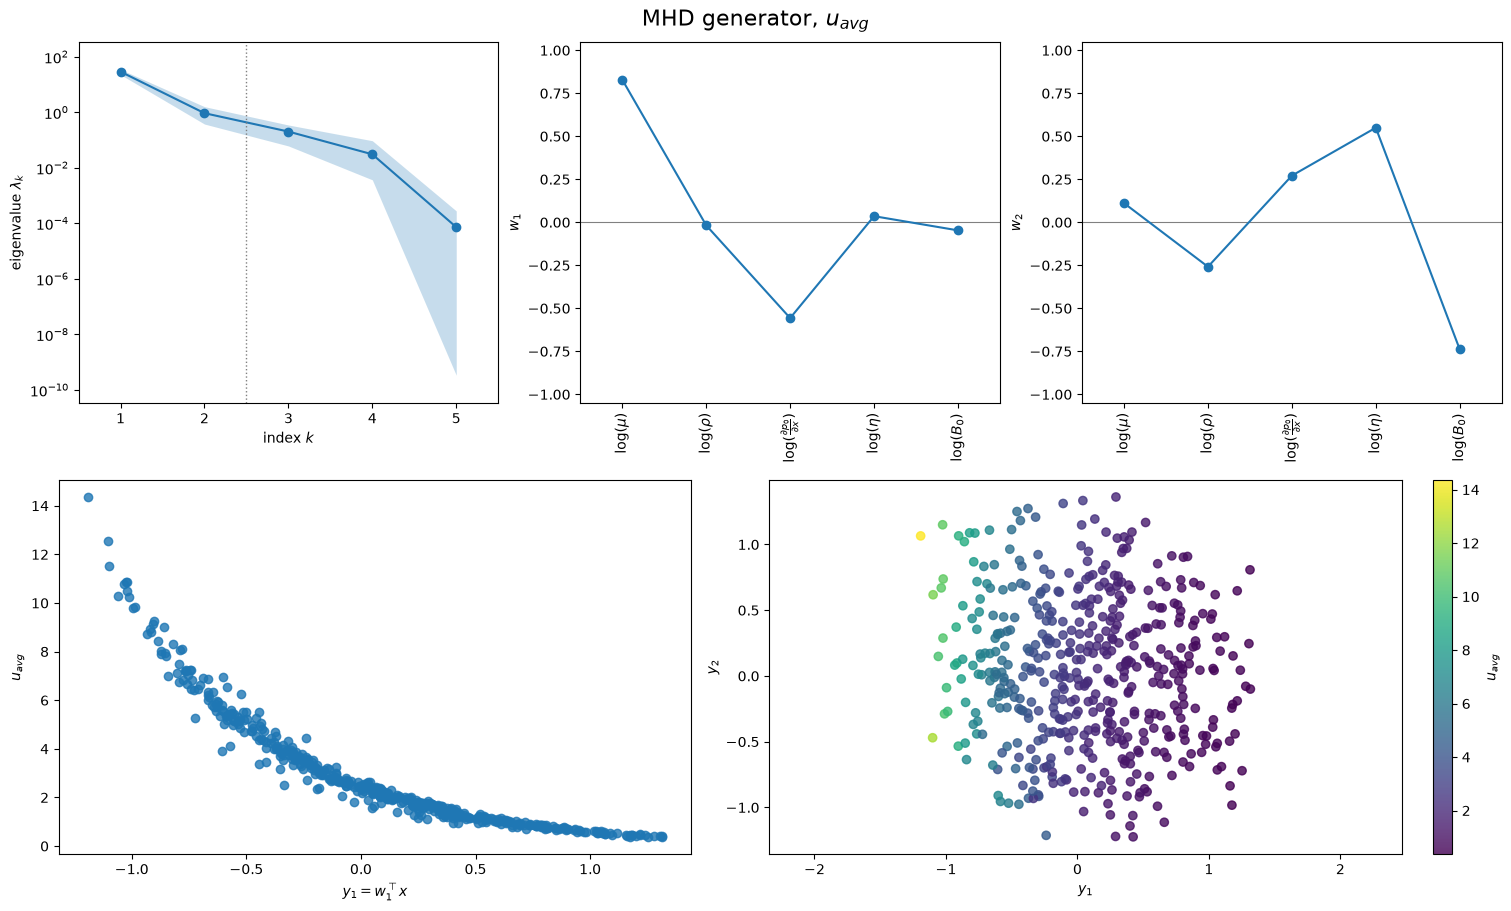

In [9]:
_, X, f, _ = gen['u_avg']
plot_case(gen_sub['u_avg'], np.log(X), f, r'$u_{avg}$', r'MHD generator, $u_{avg}$', interval='minmax')

We can see an order-of-magnitude drop between the first and second eigenvalues ($\lambda_1/\lambda_2 = 31.2$) and a tight 1-dimensional trend in the summary plot that we might expect based on this decay. However, the rest of the decay is not as pronounced as with the Hartmann problem; we see the most significant decay between the fourth and fifth values ($\lambda_5$ is 0.000242% of the sum of the eigenvalues; [[1]](https://doi.org/10.1002/sam.11355) reports 0.00024%), indicating that it would take the full 4-dimensional subspace predicted by the analysis above to fully characterize output, though the trends in the summary plots are tight. The eigenvectors indicate that the most important variables are viscosity and pressure gradient, which are also the most important parameters for the Hartmann problem. The eigenvectors match [[1]](https://doi.org/10.1002/sam.11355), Fig. 5B, including the signs.

We'll now show plots for $B_{ind}$.

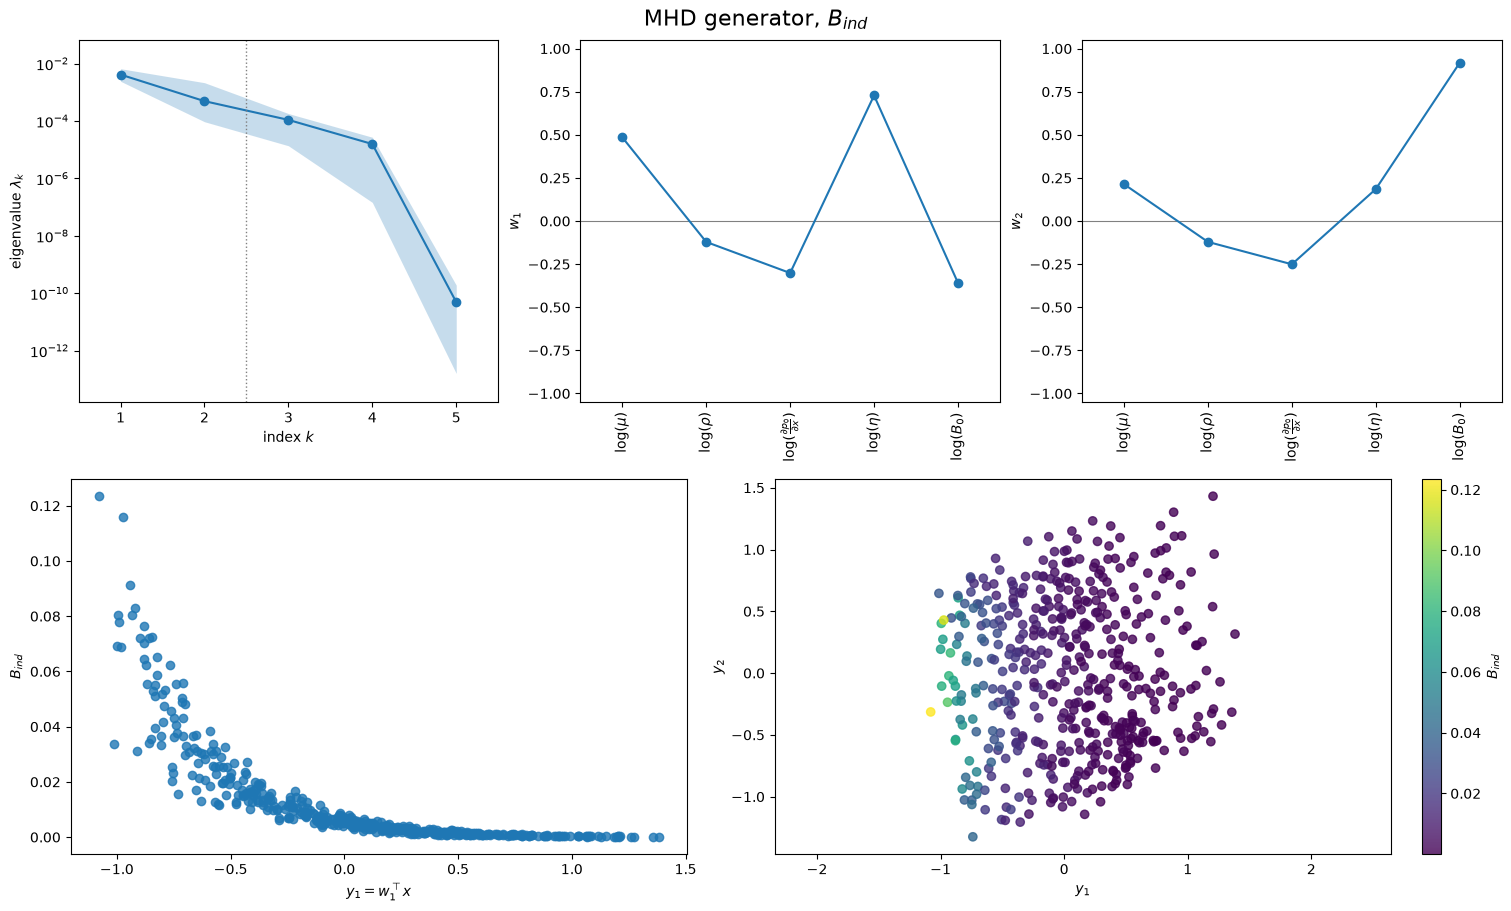

In [10]:
_, X, f, _ = gen['B_ind']
plot_case(gen_sub['B_ind'], np.log(X), f, r'$B_{ind}$', r'MHD generator, $B_{ind}$', interval='minmax')

Again, our observations are similar to those of $u_{avg}$; the eigenvalue decay is not as pronounced as with the Hartmann problem ($\lambda_5$ is 0.000001% of the sum; [[1]](https://doi.org/10.1002/sam.11355) reports 0.000001%) and the trends in each summary plot are tight, but imperfect. There is some notable deviation from the trend in the 1-dimensional summary plot when the first active variable is negative (with $\mathbf w_1$ oriented so that its first component, for $\log(\mu)$, is positive, which also makes its $\log(\eta)$ component positive); a modeller might consider using a higher-dimensional subspace for approximation in this domain. The eigenvectors match [[1]](https://doi.org/10.1002/sam.11355), Fig. 6B, including the signs.

### Conclusions

These examples show that the conclusions of the active subspace method are consistent with traditional dimensional analysis. Additionally, there is general consistency between the Hartmann and generator models regarding which parameters are important in characterizing output (viscosity and pressure gradient for $u_{avg}$ and all parameters except $\rho$ for $B_{ind}$). The active subspace method could be applied in the future to help quantify uncertainty by enabling low-dimensional approximations of output that allow for parameter studies otherwise infeasible in high dimensions.

In [11]:
print(f'Total runtime {time.perf_counter() - t_start:.1f} s')

Total runtime 8.1 s
